In [1]:
import torch
import torchvision
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import zipfile
import os

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU kullanılabilir mi?", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
GPU kullanılabilir mi? True
GPU: Tesla T4


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

proje_yolu = "/content/drive/MyDrive/Beyin_Tumoru_Projesi"

zip_yolu = os.path.join(
    proje_yolu,
    "Brain_Tumor_MRI_Dataset.zip"
)

print("ZIP dosyası mevcut mu?", os.path.exists(zip_yolu))

if os.path.exists(zip_yolu):
    print("Dosya boyutu (MB):", round(os.path.getsize(zip_yolu) / (1024 * 1024), 2))

ZIP dosyası mevcut mu? True
Dosya boyutu (MB): 157.04


In [6]:
import zipfile

with zipfile.ZipFile(zip_yolu, "r") as zip_ref:
    dosyalar = zip_ref.namelist()

print("ZIP içindeki ilk 15 yol:")
for dosya in dosyalar[:15]:
    print(dosya)

print("\nAna klasörler:")
print(sorted(set(dosya.split("/")[0] for dosya in dosyalar)))

ZIP içindeki ilk 15 yol:
Testing/glioma/Te-gl_1.jpg
Testing/glioma/Te-gl_10.jpg
Testing/glioma/Te-gl_100.jpg
Testing/glioma/Te-gl_101.jpg
Testing/glioma/Te-gl_102.jpg
Testing/glioma/Te-gl_103.jpg
Testing/glioma/Te-gl_104.jpg
Testing/glioma/Te-gl_105.jpg
Testing/glioma/Te-gl_106.jpg
Testing/glioma/Te-gl_107.jpg
Testing/glioma/Te-gl_108.jpg
Testing/glioma/Te-gl_109.jpg
Testing/glioma/Te-gl_11.jpg
Testing/glioma/Te-gl_110.jpg
Testing/glioma/Te-gl_111.jpg

Ana klasörler:
['Testing', 'Training']


In [7]:
import zipfile
import os

with zipfile.ZipFile(zip_yolu, "r") as zip_ref:
    zip_ref.extractall("/content")

veri_yolu = "/content"

print("Training klasörü:", os.path.exists(os.path.join(veri_yolu, "Training")))
print("Testing klasörü:", os.path.exists(os.path.join(veri_yolu, "Testing")))

print("Training sınıfları:", os.listdir("/content/Training"))
print("Testing sınıfları:", os.listdir("/content/Testing"))

Training klasörü: True
Testing klasörü: True
Training sınıfları: ['pituitary', 'meningioma', 'notumor', 'glioma']
Testing sınıfları: ['pituitary', 'meningioma', 'notumor', 'glioma']


In [8]:
import pandas as pd
import os

csv_yolu = "/content/drive/MyDrive/Beyin_Tumoru_Projesi/veri_bolunmesi"

train_df = pd.read_csv(os.path.join(csv_yolu, "train.csv"))
val_df = pd.read_csv(os.path.join(csv_yolu, "val.csv"))
test_df = pd.read_csv(os.path.join(csv_yolu, "test.csv"))

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nTrain sınıf dağılımı:")
print(train_df["sinif"].value_counts().sort_index())

print("\nValidation sınıf dağılımı:")
print(val_df["sinif"].value_counts().sort_index())

print("\nTest sınıf dağılımı:")
print(test_df["sinif"].value_counts().sort_index())

Train: (4480, 2)
Validation: (1120, 2)
Test: (1600, 2)

Train sınıf dağılımı:
sinif
glioma        1120
meningioma    1120
notumor       1120
pituitary     1120
Name: count, dtype: int64

Validation sınıf dağılımı:
sinif
glioma        280
meningioma    280
notumor       280
pituitary     280
Name: count, dtype: int64

Test sınıf dağılımı:
sinif
glioma        400
meningioma    400
notumor       400
pituitary     400
Name: count, dtype: int64


In [9]:
from pathlib import Path

def goruntu_yolu(dosya):
    return Path("/content") / dosya

for df_adi, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    ornek_yol = goruntu_yolu(df.iloc[0]["dosya"])

    print(f"{df_adi} örnek görüntü:")
    print(ornek_yol)
    print("Dosya mevcut mu?", ornek_yol.exists())
    print("-" * 40)

Train örnek görüntü:
/content/Training/glioma/Tr-gl_1.jpg
Dosya mevcut mu? True
----------------------------------------
Validation örnek görüntü:
/content/Training/glioma/Tr-gl_10.jpg
Dosya mevcut mu? True
----------------------------------------
Test örnek görüntü:
/content/Testing/glioma/Te-gl_1.jpg
Dosya mevcut mu? True
----------------------------------------


Görüntü boyutu: (512, 512)
Görüntü modu: L
Sınıf: glioma


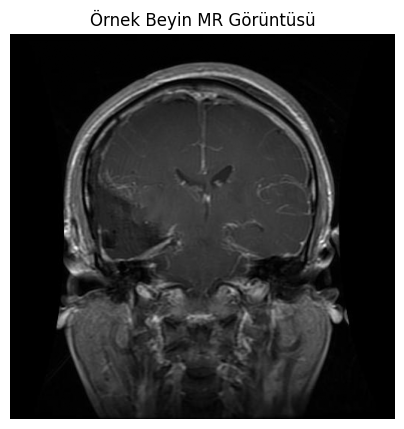

In [10]:
from PIL import Image
import matplotlib.pyplot as plt

ornek_dosya = train_df.iloc[0]["dosya"]
ornek_yol = f"/content/{ornek_dosya}"

goruntu = Image.open(ornek_yol)

print("Görüntü boyutu:", goruntu.size)
print("Görüntü modu:", goruntu.mode)
print("Sınıf:", train_df.iloc[0]["sinif"])

plt.figure(figsize=(5, 5))
plt.imshow(goruntu, cmap="gray")
plt.title("Örnek Beyin MR Görüntüsü")
plt.axis("off")
plt.show()

In [11]:
from torchvision import transforms

IMG_SIZE = 224

donusum = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5],
        std=[0.5]
    )
])

islenmis_goruntu = donusum(goruntu)

print("Dönüştürülmüş görüntü boyutu:", islenmis_goruntu.shape)
print("Minimum piksel değeri:", islenmis_goruntu.min().item())
print("Maksimum piksel değeri:", islenmis_goruntu.max().item())

Dönüştürülmüş görüntü boyutu: torch.Size([1, 224, 224])
Minimum piksel değeri: -1.0
Maksimum piksel değeri: 0.7882353067398071


In [12]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

# Sınıfların sayısal karşılıkları
siniflar = {
    "glioma": 0,
    "meningioma": 1,
    "notumor": 2,
    "pituitary": 3
}

IMG_SIZE = 224

# Görüntü dönüşümleri
donusum = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

class BrainTumorDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        dosya = self.dataframe.iloc[index]["dosya"]
        sinif = self.dataframe.iloc[index]["sinif"]

        yol = os.path.join("/content", dosya)

        goruntu = Image.open(yol).convert("L")

        if self.transform:
            goruntu = self.transform(goruntu)

        etiket = siniflar[sinif]

        return goruntu, etiket

print("Dataset sınıfı oluşturuldu.")

Dataset sınıfı oluşturuldu.


In [13]:
BATCH_SIZE = 32

# Dataset nesneleri
train_dataset = BrainTumorDataset(train_df, transform=donusum)
val_dataset = BrainTumorDataset(val_df, transform=donusum)
test_dataset = BrainTumorDataset(test_df, transform=donusum)

# DataLoader nesneleri
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Train batch sayısı:", len(train_loader))
print("Validation batch sayısı:", len(val_loader))
print("Test batch sayısı:", len(test_loader))

Train batch sayısı: 140
Validation batch sayısı: 35
Test batch sayısı: 50


Görüntü batch boyutu: torch.Size([32, 1, 224, 224])
Etiket batch boyutu: torch.Size([32])
İlk 10 etiket: [2, 0, 2, 2, 3, 2, 2, 0, 3, 0]


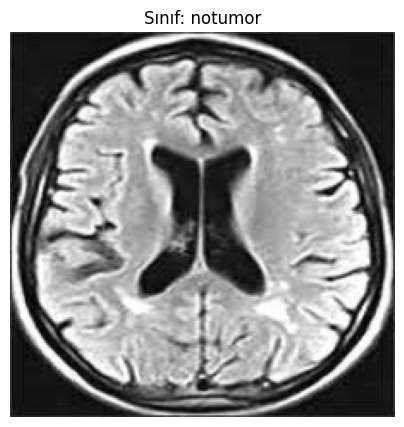

In [14]:
goruntuler, etiketler = next(iter(train_loader))

print("Görüntü batch boyutu:", goruntuler.shape)
print("Etiket batch boyutu:", etiketler.shape)
print("İlk 10 etiket:", etiketler[:10].tolist())

# İlk görüntüyü görselleştirelim
plt.figure(figsize=(5, 5))

goruntu_goster = goruntuler[0].squeeze() * 0.5 + 0.5

plt.imshow(goruntu_goster, cmap="gray")
plt.title(f"Sınıf: {list(siniflar.keys())[etiketler[0].item()]}")
plt.axis("off")
plt.show()

In [16]:
import torch.nn as nn

class BrainTumorCNN(nn.Module):
    def __init__(self):
        super(BrainTumorCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, 4)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x


model = BrainTumorCNN().to(device)

print("Model cihazı:", device)
print("Toplam parametre sayısı:", sum(p.numel() for p in model.parameters()))

Model cihazı: cuda
Toplam parametre sayısı: 110148


In [17]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 20

print("Kayıp fonksiyonu:", criterion)
print("Optimizasyon:", optimizer)
print("Epoch sayısı:", EPOCHS)

Kayıp fonksiyonu: CrossEntropyLoss()
Optimizasyon: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Epoch sayısı: 20


In [18]:
import os
import torch

# Model kayıt yolu
model_klasoru = "/content/drive/MyDrive/Beyin_Tumoru_Projesi/modeller"
os.makedirs(model_klasoru, exist_ok=True)

model_yolu = os.path.join(model_klasoru, "cnn_best.pth")

# Eğitim sonuçlarını saklayacağımız listeler
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_loss = float("inf")

for epoch in range(EPOCHS):

    # EĞİTİM
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for goruntuler, etiketler in train_loader:

        goruntuler = goruntuler.to(device)
        etiketler = etiketler.to(device)

        optimizer.zero_grad()

        outputs = model(goruntuler)
        loss = criterion(outputs, etiketler)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * goruntuler.size(0)

        _, tahminler = torch.max(outputs, 1)

        train_total += etiketler.size(0)
        train_correct += (tahminler == etiketler).sum().item()

    train_loss = train_loss / train_total
    train_acc = 100 * train_correct / train_total

    # DOĞRULAMA
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for goruntuler, etiketler in val_loader:

            goruntuler = goruntuler.to(device)
            etiketler = etiketler.to(device)

            outputs = model(goruntuler)
            loss = criterion(outputs, etiketler)

            val_loss += loss.item() * goruntuler.size(0)

            _, tahminler = torch.max(outputs, 1)

            val_total += etiketler.size(0)
            val_correct += (tahminler == etiketler).sum().item()

    val_loss = val_loss / val_total
    val_acc = 100 * val_correct / val_total

    # Sonuçları kaydet
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

    # En iyi modeli kaydet
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": val_loss,
            "val_acc": val_acc
        }, model_yolu)

        print("  -> En iyi model kaydedildi.")

print("\nEğitim tamamlandı!")
print("En iyi model:", model_yolu)

Epoch [1/20] Train Loss: 0.9330 | Train Acc: 63.53% | Val Loss: 0.7320 | Val Acc: 74.29%
  -> En iyi model kaydedildi.
Epoch [2/20] Train Loss: 0.7374 | Train Acc: 70.58% | Val Loss: 1.3607 | Val Acc: 45.18%
Epoch [3/20] Train Loss: 0.6755 | Train Acc: 73.44% | Val Loss: 0.5579 | Val Acc: 78.66%
  -> En iyi model kaydedildi.
Epoch [4/20] Train Loss: 0.5918 | Train Acc: 76.94% | Val Loss: 1.0520 | Val Acc: 56.70%
Epoch [5/20] Train Loss: 0.5597 | Train Acc: 79.33% | Val Loss: 0.8512 | Val Acc: 68.57%
Epoch [6/20] Train Loss: 0.5151 | Train Acc: 80.11% | Val Loss: 0.5640 | Val Acc: 76.43%
Epoch [7/20] Train Loss: 0.4987 | Train Acc: 81.03% | Val Loss: 0.8933 | Val Acc: 65.98%
Epoch [8/20] Train Loss: 0.4667 | Train Acc: 83.04% | Val Loss: 1.7548 | Val Acc: 48.30%
Epoch [9/20] Train Loss: 0.4552 | Train Acc: 83.28% | Val Loss: 0.5332 | Val Acc: 79.38%
  -> En iyi model kaydedildi.
Epoch [10/20] Train Loss: 0.4476 | Train Acc: 83.44% | Val Loss: 4.2881 | Val Acc: 42.32%
Epoch [11/20] Train

In [19]:

# En iyi CNN modelini yükleme

import torch
import os

model_yolu = "/content/drive/MyDrive/Beyin_Tumoru_Projesi/modeller/cnn_best.pth"

# Model mimarisini oluştur
model = BrainTumorCNN().to(device)

# Kaydedilen ağırlıkları yükle
checkpoint = torch.load(model_yolu, map_location=device)

model.load_state_dict(checkpoint["model_state_dict"])

# Test moduna al
model.eval()

print("Model başarıyla yüklendi!")
print("En iyi epoch:", checkpoint["epoch"])
print("Validation Accuracy:", checkpoint["val_acc"])
print("Validation Loss:", checkpoint["val_loss"])


Model başarıyla yüklendi!
En iyi epoch: 18
Validation Accuracy: 85.89285714285714
Validation Loss: 0.37699890754052573


In [20]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

y_true = []
y_pred = []

model.eval()

with torch.no_grad():
    for goruntuler, etiketler in test_loader:

        goruntuler = goruntuler.to(device)

        outputs = model(goruntuler)
        tahminler = torch.argmax(outputs, dim=1)

        y_true.extend(etiketler.numpy())
        y_pred.extend(tahminler.cpu().numpy())

print("Test tahminleri tamamlandı!")
print("Toplam test görüntüsü:", len(y_true))
print("Tahmin sayısı:", len(y_pred))


Test tahminleri tamamlandı!
Toplam test görüntüsü: 1600
Tahmin sayısı: 1600


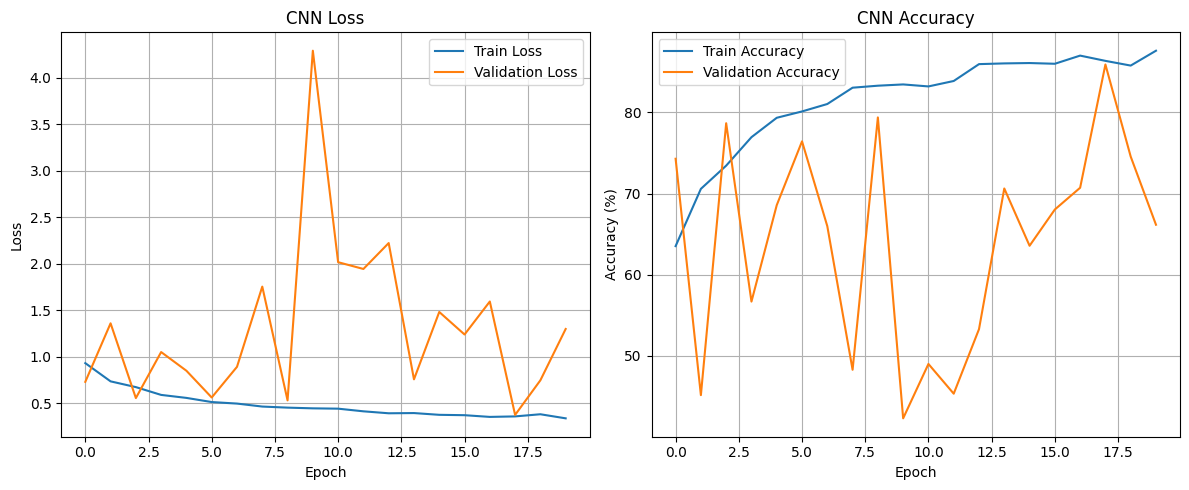

Grafik kaydedildi: /content/drive/MyDrive/Beyin_Tumoru_Projesi/results/cnn_training_curves.png


In [24]:
sonuc_klasoru = "/content/drive/MyDrive/Beyin_Tumoru_Projesi/results"
os.makedirs(sonuc_klasoru, exist_ok=True)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(history["train_acc"], label="Train Accuracy")
plt.plot(history["val_acc"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid()

plt.tight_layout()

grafik_yolu = os.path.join(sonuc_klasoru, "cnn_training_curves.png")
plt.savefig(grafik_yolu, dpi=300, bbox_inches="tight")
plt.show()

print("Grafik kaydedildi:", grafik_yolu)

In [25]:
checkpoint = torch.load(model_yolu, map_location=device)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Yüklenen epoch:", checkpoint["epoch"])
print("Doğrulama doğruluğu:", f'{checkpoint["val_acc"]:.2f}%')
print("Model test değerlendirmesine hazır.")

Yüklenen epoch: 18
Doğrulama doğruluğu: 85.89%
Model test değerlendirmesine hazır.


In [26]:
tum_tahminler = []
gercek_etiketler = []

model.eval()

with torch.no_grad():
    for goruntuler, etiketler in test_loader:
        goruntuler = goruntuler.to(device)

        outputs = model(goruntuler)
        _, tahminler = torch.max(outputs, 1)

        tum_tahminler.extend(tahminler.cpu().numpy())
        gercek_etiketler.extend(etiketler.numpy())

print("Test görüntüsü sayısı:", len(gercek_etiketler))
print("Tahmin sayısı:", len(tum_tahminler))
print("Test tahminleri tamamlandı.")

Test görüntüsü sayısı: 1600
Tahmin sayısı: 1600
Test tahminleri tamamlandı.


In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

accuracy = accuracy_score(gercek_etiketler, tum_tahminler)
precision = precision_score(gercek_etiketler, tum_tahminler, average="macro")
recall = recall_score(gercek_etiketler, tum_tahminler, average="macro")
f1 = f1_score(gercek_etiketler, tum_tahminler, average="macro")

print("CNN TEST SONUÇLARI")
print("----------------------")
print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1-Score : {f1 * 100:.2f}%")

print("\nSINIF BAZLI SONUÇLAR")
print(classification_report(
    gercek_etiketler,
    tum_tahminler,
    target_names=["glioma", "meningioma", "notumor", "pituitary"],
    digits=4
))

CNN TEST SONUÇLARI
----------------------
Accuracy : 76.75%
Precision: 79.85%
Recall   : 76.75%
F1-Score : 75.88%

SINIF BAZLI SONUÇLAR
              precision    recall  f1-score   support

      glioma     0.9735    0.5500    0.7029       400
  meningioma     0.6753    0.5875    0.6283       400
     notumor     0.6633    1.0000    0.7976       400
   pituitary     0.8818    0.9325    0.9064       400

    accuracy                         0.7675      1600
   macro avg     0.7985    0.7675    0.7588      1600
weighted avg     0.7985    0.7675    0.7588      1600



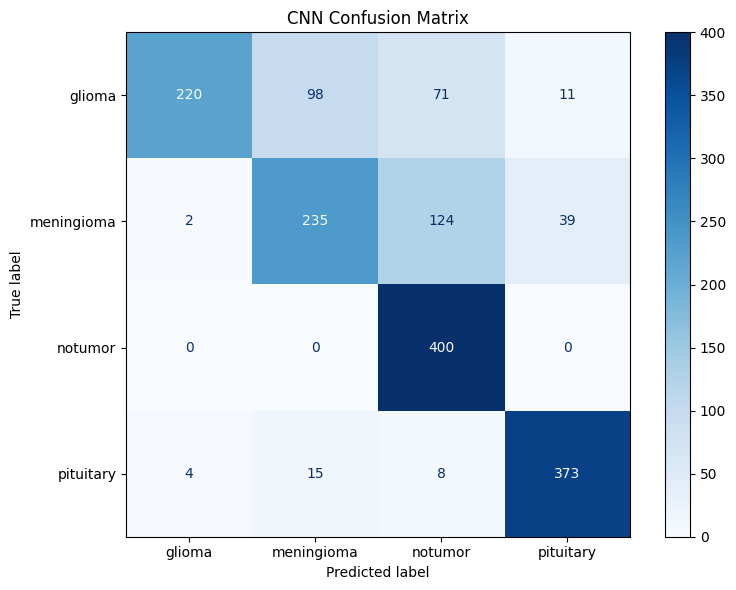

Confusion matrix kaydedildi: /content/drive/MyDrive/Beyin_Tumoru_Projesi/results/cnn_confusion_matrix.png


In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

sinif_isimleri = ["glioma", "meningioma", "notumor", "pituitary"]

cm = confusion_matrix(gercek_etiketler, tum_tahminler)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=sinif_isimleri
)

disp.plot(cmap="Blues", values_format="d", ax=ax)
plt.title("CNN Confusion Matrix")
plt.tight_layout()

cm_yolu = os.path.join(sonuc_klasoru, "cnn_confusion_matrix.png")
plt.savefig(cm_yolu, dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix kaydedildi:", cm_yolu)